# Problem 2 (Easy Version) – VGG16 Classifier: airplane / automobile / truck
**Kaggle setup:** add the `cifar10` dataset (+ Add Input) → Accelerator: **GPU** → Run All.

**VGG16 weights (needs ONE of these):**
- **Option A (easy):** Session options → **Internet: ON** (Kaggle may ask for phone verification), or
- **Option B (no internet):** `+ Add Input` → search **"keras pretrained models"** (or "vgg16 notop weights") and add a dataset that contains the file `vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5`. Step 1b below finds and installs it automatically.

**The 7 steps (easy to remember):**
1. Import libraries → 2. Load the 3 classes → 3. Preprocess for VGG16 → 4. Build model (VGG16 + our classifier) → 5. Callbacks → 6. Train two models (entire / partial fine-tuning) → 7. Plot loss curves and compare.

## Step 1: Import libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Step 1b: Make the pre-trained VGG16 weights available (works with or without Internet)

In [2]:
import glob, shutil, socket

weights_name = "vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"

# If you copied the weights file (e.g. from a pen drive) put its full path here, else leave None.
# Example (Windows): WEIGHTS_FILE = r"D:\\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"
WEIGHTS_FILE = None

models_dir = os.path.expanduser("~/.keras/models")      # Keras looks for weights here first
os.makedirs(models_dir, exist_ok=True)
target = os.path.join(models_dir, weights_name)

# 1) Find the weights file (manual path, current folder, or Kaggle input) and copy it for Keras.
if not os.path.exists(target):
    candidates = []
    if WEIGHTS_FILE:
        candidates.append(WEIGHTS_FILE)
    candidates += glob.glob("./**/" + weights_name, recursive=True)
    candidates += glob.glob("/kaggle/input/**/" + weights_name, recursive=True)
    candidates = [c for c in candidates if os.path.exists(c)]
    if candidates:
        shutil.copy(candidates[0], target)
        print("Weights copied from:", candidates[0])

# 2) Is Internet ON (so Keras can download the weights)?
try:
    socket.create_connection(("storage.googleapis.com", 443), timeout=3).close()
    internet_on = True
except OSError:
    internet_on = False

USE_IMAGENET = os.path.exists(target) or internet_on
print("Weights file available:", os.path.exists(target), "| Internet ON:", internet_on)

if USE_IMAGENET:
    print("OK: pre-trained ImageNet weights will be used.")
else:
    print("WARNING: no pre-trained weights and no Internet!")
    print("The code will still RUN, but VGG16 will start from RANDOM weights (NOT pre-trained).")
    print("Fix: copy", weights_name, "to", models_dir, "or set WEIGHTS_FILE above.")

Weights file available: False | Internet ON: False
The code will still RUN, but VGG16 will start from RANDOM weights (NOT pre-trained).
Fix: copy vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5 to /root/.keras/models or set WEIGHTS_FILE above.


## Step 2: Load the dataset (only airplane, automobile, truck)

In [3]:
DATASET_PATH = "/kaggle/input/datasets/oxcdcd/cifar10/cifar10"
class_names = ["airplane", "automobile", "truck"]      # labels: 0, 1, 2

def load_data(folder):
    images, labels = [], []
    for label, name in enumerate(class_names):
        path = os.path.join(folder, name)               # e.g. .../train/airplane
        for file in os.listdir(path):
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                img = Image.open(os.path.join(path, file)).convert("RGB").resize((32, 32))
                images.append(np.array(img))
                labels.append(label)
    return np.array(images), np.array(labels)

x_train, y_train = load_data(os.path.join(DATASET_PATH, "train"))
x_test,  y_test  = load_data(os.path.join(DATASET_PATH, "test"))

# Shuffle the training data (it was loaded class by class)
idx = np.random.permutation(len(x_train))
x_train, y_train = x_train[idx], y_train[idx]

print("Train:", x_train.shape, "| Test:", x_test.shape)
print("Images per class (train):", np.bincount(y_train))

Train: (15000, 32, 32, 3) | Test: (3000, 32, 32, 3)
Images per class (train): [5000 5000 5000]


## Step 3: Preprocess for VGG16

In [4]:
# VGG16 needs its own preprocessing (same as ImageNet training)
x_train = preprocess_input(x_train.astype("float32"))
x_test  = preprocess_input(x_test.astype("float32"))

## Step 4: Build the model
`build_model(partial)`: VGG16 (pre-trained on ImageNet, without its top) + our own classifier for 3 classes.
- `partial=False` → **(i) entire** VGG16 is fine-tuned (all layers trainable).
- `partial=True`  → **(ii) partially** fine-tuned: only the last block (`block5`) is trainable, earlier blocks are frozen.

In [5]:
def build_model(partial, lr):
    weights = "imagenet" if USE_IMAGENET else None       # pre-trained weights (None only if unavailable)
    base = VGG16(weights=weights, include_top=False, input_shape=(32, 32, 3))

    base.trainable = True                      # start with all layers trainable
    if partial:
        for layer in base.layers:
            if not layer.name.startswith("block5"):
                layer.trainable = False        # freeze blocks 1-4

    model = Sequential([
        base,
        Flatten(),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(3, activation="softmax"),        # 3 classes
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",   # labels are integers 0,1,2
                  metrics=["accuracy"])
    return model

## Step 5: Callbacks (stop training automatically and reduce the learning rate)

In [6]:
def get_callbacks():
    return [
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),   # automatic stop
        ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2),              # reduce learning rate
    ]

## Step 6a: (i) Fine-tune the ENTIRE pre-trained VGG16

In [7]:
model_full = build_model(partial=False, lr=1e-5)      # small learning rate for the whole network
hist_full = model_full.fit(x_train, y_train,
                           validation_split=0.2,      # 20% of training data for validation
                           epochs=15, batch_size=64,
                           callbacks=get_callbacks())

I0000 00:00:1792957670.813908      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792957670.819466      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/15
  2/188 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.3750 - loss: 1.0870 

I0000 00:00:1792957686.233465      68 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.5677 - loss: 0.8988 - val_accuracy: 0.6497 - val_loss: 0.7576 - learning_rate: 1.0000e-05
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.6801 - loss: 0.7200 - val_accuracy: 0.7063 - val_loss: 0.6597 - learning_rate: 1.0000e-05
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.7342 - loss: 0.6234 - val_accuracy: 0.7453 - val_loss: 0.5956 - learning_rate: 1.0000e-05
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 58ms/step - accuracy: 0.7738 - loss: 0.5511 - val_accuracy: 0.7673 - val_loss: 0.5587 - learning_rate: 1.0000e-05
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 58ms/step - accuracy: 0.8081 - loss: 0.4873 - val_accuracy: 0.7720 - val_loss: 0.5376 - learning_rate: 1.0000e-05
Epoch 6/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8356 - loss: 0.4316 - val_accuracy: 0.7863 - val_loss: 0.5251 - learning_rate: 1.0000e-05
Epoch 7/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accura

## Step 6b: (ii) Fine-tune a PARTIALLY pre-trained VGG16 (only block5 trained)

In [8]:
model_part = build_model(partial=True, lr=1e-4)
hist_part = model_part.fit(x_train, y_train,
                           validation_split=0.2,
                           epochs=15, batch_size=64,
                           callbacks=get_callbacks())

Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.5207 - loss: 0.9410 - val_accuracy: 0.6140 - val_loss: 0.8241 - learning_rate: 1.0000e-04
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6237 - loss: 0.8098 - val_accuracy: 0.6397 - val_loss: 0.7662 - learning_rate: 1.0000e-04
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6470 - loss: 0.7621 - val_accuracy: 0.6440 - val_loss: 0.7562 - learning_rate: 1.0000e-04
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6742 - loss: 0.7234 - val_accuracy: 0.6763 - val_loss: 0.7115 - learning_rate: 1.0000e-04
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6892 - loss: 0.6961 - val_accuracy: 0.6170 - val_loss: 0.7799 - learning_rate: 1.0000e-04
Epoch 6/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.7022 - loss: 0.6719 - val_accuracy: 0.6780 - val_loss: 0.6912 - learning_rate: 1.0000e-04
Epoch 7/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - ac

## Step 7: Training and validation loss curves + comparison

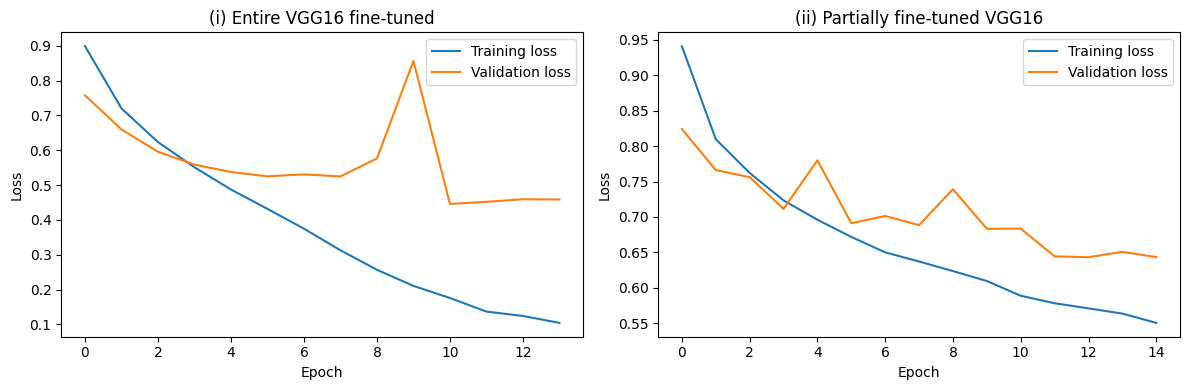

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_full.history["loss"], label="Training loss")
plt.plot(hist_full.history["val_loss"], label="Validation loss")
plt.title("(i) Entire VGG16 fine-tuned")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_part.history["loss"], label="Training loss")
plt.plot(hist_part.history["val_loss"], label="Validation loss")
plt.title("(ii) Partially fine-tuned VGG16")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# Compare both models on the test data
loss_full, acc_full = model_full.evaluate(x_test, y_test, verbose=0)
loss_part, acc_part = model_part.evaluate(x_test, y_test, verbose=0)

print(f"(i)  Entire fine-tuned   : test accuracy = {acc_full*100:.2f} %")
print(f"(ii) Partial fine-tuned  : test accuracy = {acc_part*100:.2f} %")

(i)  Entire fine-tuned   : test accuracy = 83.93 %
(ii) Partial fine-tuned  : test accuracy = 72.87 %


## 

Short answers for the viva
- **Fine-tuning:** continue training a pre-trained network on our own data so its weights adapt to our task.
- **(i) Entire:** all layers are updated, so it can fit best but is slower and needs a very small learning rate (1e-5) to avoid destroying the pre-trained weights.
- **(ii) Partial:** early layers (edges, textures) are already good, so they are frozen; only the last block and our classifier are trained. It is faster and less prone to overfitting.
- **EarlyStopping:** stops training when validation loss stops improving (and restores the best weights).
- **ReduceLROnPlateau:** multiplies the learning rate by 0.2 when validation loss stops improving.
- **Why `sparse_categorical_crossentropy`?** The labels are integers (0, 1, 2), not one-hot vectors.
- **Why `softmax` with 3 neurons?** We have 3 classes and need class probabilities.